# AI 모의면접 평가 파이프라인 — 영상 1개 전 과정 시연

```
면접 영상 → [AI 분석] → 지표 52개 → [평가모델] → 항목별 점수 7개 → 총점 → 리포트
```

각 단계를 하나씩 실행하며 중간 결과를 확인한다.

**주의**: 예측 단계에서는 데모 영상 촬영자의 영상을 학습 데이터에서 **전부 제외**한다.
같은 사람의 다른 영상이 학습에 들어가면 성능이 부풀려지기 때문(데이터 누수).

## STEP 0. 환경 준비

In [1]:
import os, sys, json, time, subprocess, ctypes, math
from pathlib import Path
from collections import Counter

# onnxruntime CUDA는 libcudnn.so.9 가 필요한데 LD_LIBRARY_PATH 는 프로세스 시작 시 고정된다.
# 주피터 커널이 이미 떠 있으므로 .so 를 직접 프로세스에 적재해 해결한다.
for lib in ["libcudnn.so.9", "libcudnn_graph.so.9", "libcudnn_engines_precompiled.so.9",
            "libcudnn_engines_runtime_compiled.so.9", "libcudnn_heuristic.so.9",
            "libcudnn_ops.so.9", "libcudnn_cnn.so.9", "libcudnn_adv.so.9"]:
    try:
        ctypes.CDLL(f"/opt/conda/lib/python3.12/site-packages/nvidia/cudnn/lib/{lib}",
                    mode=ctypes.RTLD_GLOBAL)
    except OSError:
        pass
os.environ["RTMPOSE_CUDA_READY"] = "1"

CSM = Path("/workspace/CSM")
sys.path += [str(CSM / "verbal_module"), str(CSM / "backend"),
             str(CSM / "nonverbal_module")]

import cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "DejaVu Sans"

print("준비 완료")

준비 완료


## STEP 1. 영상 선택

`이영은_bad` — 일부러 못하는 모습을 연기한 영상. 사람이 매긴 실제 점수는 **35.0점**이다.

영상 ID   : 이영은_bad  (촬영자: 이영은)
길이      : 79.2초  (1901프레임, 24.0fps)
해상도    : 1280 x 720


/opt/conda/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/conda/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 50689 (\N{HANGUL SYLLABLE YEONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/conda/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 51008 (\N{HANGUL SYLLABLE EUN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


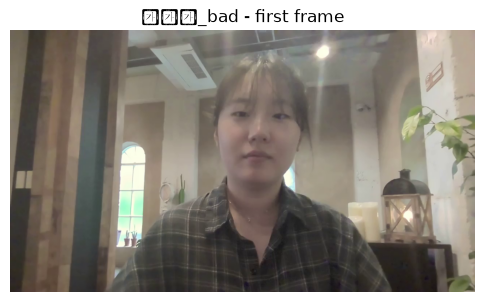

In [2]:
VIDEO_ID = "이영은_bad"
VIDEO_PATH = CSM / "eval_model/data/raw_videos/2_bad" / f"{VIDEO_ID}.mp4"
PERSON = VIDEO_ID.split("_")[0]

cap = cv2.VideoCapture(str(VIDEO_PATH))
fps = cap.get(cv2.CAP_PROP_FPS)
n_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
w, h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
ok, first_frame = cap.read()
cap.release()

print(f"영상 ID   : {VIDEO_ID}  (촬영자: {PERSON})")
print(f"길이      : {n_frames/fps:.1f}초  ({n_frames}프레임, {fps:.1f}fps)")
print(f"해상도    : {w} x {h}")

plt.figure(figsize=(6, 3.5))
plt.imshow(cv2.cvtColor(first_frame, cv2.COLOR_BGR2RGB))
plt.axis("off"); plt.title(f"{VIDEO_ID} - first frame"); plt.show()

## STEP 2-1. 음성 분석

영상에서 오디오를 뽑아 Whisper로 전사한 뒤, 발화속도·습관어·말더듬·침묵·음량을 계산한다.
`verbal_module/api.py` 를 그대로 쓴다 (실제 서비스와 동일한 코드 경로).

In [3]:
# Whisper를 GPU로 (원본 transcriber.py 는 CPU 고정이라 로더만 교체)
import analyzers, analyzers.transcriber as transcriber
def _gpu_loader(model_size="medium"):
    from faster_whisper import WhisperModel
    return WhisperModel(model_size, device="cuda", compute_type="float16")
analyzers.load_model = transcriber.load_model = _gpu_loader

AUDIO = CSM / "eval_model/data/_audio_tmp" / f"{VIDEO_ID}.wav"
AUDIO.parent.mkdir(parents=True, exist_ok=True)
if not AUDIO.exists():
    subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", str(VIDEO_PATH),
                    "-vn", "-ac", "1", "-ar", "16000", str(AUDIO)], check=True)

import api as lang_api
t0 = time.time()
report = lang_api.analyze_file(str(AUDIO))
print(f"음성 분석 완료 ({time.time()-t0:.1f}초)\n")

m, raw = report["metrics"], report["raw_data"]
print("[전사 결과]")
print(raw["transcript"][:200], "...\n")
print(f"발화 속도       : {m['speech_rate']['spm']} spm ({m['speech_rate']['label']})")
print(f"습관어          : {m['filler_word']['count']}회")
print(f"말더듬          : {m['stuttering']['count']}회")
print(f"긴 침묵(2초+)   : {m['long_pauses']['count']}회")
print(f"음량 변동계수   : {m['volume_stability']['cv']}  ({m['volume_stability']['label']})")
print(f"총 길이/순수발화: {raw['total_duration_sec']}초 / {raw['pure_speech_time_sec']}초")

[Tokenizer] KoNLPy okt 로드 완료 (use_pos=False)
[NgramLM] 로드 완료: /workspace/CSM/verbal_module/analyzers/../models/ngram_model.pkl


음성 분석 완료 (9.9초)

[전사 결과]
저는 일단 성실하다고 하는 게 강점인 것 같습니다. 그리고 일단 뭐든 열심히 하는 편이고요. 주변에서도 항상 성실하다고 얘기해 주는 것 같고 사실 딱 하나로 꼽기들도 어렵긴 한데 굳이 말하면 책임감도 있는 편이고 맡은 일을 잘 하라고 노력하고 있습니다. 팀 프로젝트 같은 경우에도 맡은 데서는 제가 열심히 했고요 그게 장점이라고 할 수 있을 것 같습니다 약점 ...

발화 속도       : 261.3 spm (느림)
습관어          : 4회
말더듬          : 0회
긴 침묵(2초+)   : 3회
음량 변동계수   : 0.5894  (안정적)
총 길이/순수발화: 74.43초 / 55.56초


In [4]:
# 감점 구간 타임스탬프 — 사용자 리포트에서 "이 구간을 다시 보세요"에 사용
print("[긴 침묵 구간]")
for p in m["long_pauses"]["occurrences"][:5]:
    print(f"  {p['start']:6.1f}s ~ {p['end']:6.1f}s  ({p['duration']:.1f}초)")
print("\n[습관어 발생 시점]")
for f in m["filler_word"]["occurrences"][:5]:
    t = f.get("time")
    stamp = f"{t:6.1f}s" if t is not None else "  시점없음"   # STT가 시점을 못 준 경우
    print(f"  {stamp}  '{f['word']}'")

[긴 침묵 구간]
    31.2s ~   34.4s  (3.3초)
    43.4s ~   45.6s  (2.2초)
    47.8s ~   54.3s  (6.6초)

[습관어 발생 시점]
    시점없음  '어'
    70.9s  '아'
    75.0s  '뭐'
    75.0s  '뭐'


## STEP 2-2. 시선 + 표정 분석

프레임을 2fps로 샘플링하며 한 번의 순회로 두 가지를 동시에 계산한다.
- **시선**: MediaPipe Face Landmarker의 blendshape(`eyeLookUp/Down/In/Out`)로 방향 판정
- **표정**: 잘라낸 얼굴 crop을 HSEmotion(EfficientNet-B2)에 넣어 8감정 분류

In [5]:
from eye_tracker import _create_detector, detect_cropped_face, analyze_gaze_bs, summarize_gaze
from hsemotion.facial_emotions import HSEmotionRecognizer

detector = _create_detector()
fer = HSEmotionRecognizer(model_name="enet_b2_8", device="cuda")

SAMPLE_FPS = 2
cap = cv2.VideoCapture(str(VIDEO_PATH))
stride = max(1, int(round(fps / SAMPLE_FPS)))
gaze_log, emotions, confs, face_crops = [], [], [], []
idx = sampled = 0
t0 = time.time()

while cap.isOpened():
    ok, frame = cap.read()
    if not ok: break
    if idx % stride == 0:
        sampled += 1
        cropped, res = detect_cropped_face(frame, detector)
        if res.face_landmarks and res.face_blendshapes:
            gaze_log.append({"time": round(idx/fps, 2),
                             "direction": analyze_gaze_bs(res.face_blendshapes[0])})
            label, scores = fer.predict_emotions(cv2.cvtColor(cropped, cv2.COLOR_BGR2RGB), logits=False)
            emotions.append(label); confs.append(float(np.max(scores)))
            if len(face_crops) < 6: face_crops.append((cropped, label, round(idx/fps,1)))
    idx += 1
cap.release()
print(f"시선+표정 분석 완료 ({time.time()-t0:.1f}초) — {sampled}프레임 샘플링, 얼굴 검출 {len(gaze_log)}개")

W0000 00:00:1790055336.861468   62147 face_landmarker_graph.cc:180] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1790055336.926303   62151 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1790055336.946547   62153 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
/opt/conda/lib/python3.12/site-packages/hsemotion/facial_emotions.py:49: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the defaul

/root/.hsemotion/enet_b2_8.pt Compose(
    Resize(size=(260, 260), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


시선+표정 분석 완료 (12.6초) — 159프레임 샘플링, 얼굴 검출 159개


In [6]:
gaze = summarize_gaze(gaze_log)
print(f"정면 응시 비율 : {gaze['gaze_ratio']*100:.1f}%")
print(f"방향별 비율    : {gaze['direction_ratios']}")
print(f"피드백         : {gaze['feedback']}")
print(f"시선 이탈 구간 : {len(gaze['deviated_segments'])}개")
for s in gaze["deviated_segments"][:5]:
    print(f"   {s['start']:6.1f}s ~ {s['end']:6.1f}s → {s['direction']}")


정면 응시 비율 : 54.0%
방향별 비율    : {'left': 0.09, 'right': 0.02, 'up': 0.0, 'down': 0.18, 'blink': 0.17}
피드백         : 시선 회피 빈번 — 자신감 부족으로 보일 수 있음
시선 이탈 구간 : 29개
      1.5s ~    1.5s → right
      4.5s ~    4.5s → left
      7.0s ~    7.0s → blink
     11.0s ~   12.0s → blink
     14.0s ~   17.5s → blink


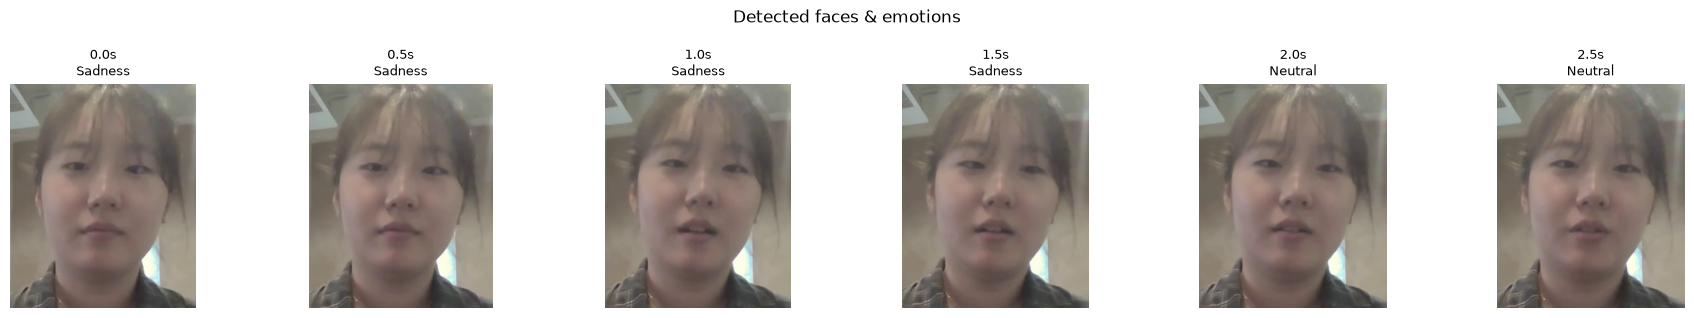

In [7]:
fig, axes = plt.subplots(1, len(face_crops), figsize=(3*len(face_crops), 3.2))
for ax, (crop, label, t) in zip(np.atleast_1d(axes), face_crops):
    ax.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)); ax.axis("off")
    ax.set_title(f"{t}s\n{label}", fontsize=9)
plt.suptitle("Detected faces & emotions"); plt.tight_layout(); plt.show()

## STEP 2-3. 자세 분석

RTMW3D-x(3D 전신 포즈)로 어깨·목·골반 좌표를 뽑아 기울기/구부정/회전을 점수화한다.
기존 `posture_rtmpose(change_model).py` 의 `PostureAnalyzer3D` 를 그대로 사용.

In [8]:
import importlib.util
spec = importlib.util.spec_from_file_location(
    "posture_mod", CSM / "nonverbal_module/posture_rtmpose_3d.py")
posture_mod = importlib.util.module_from_spec(spec); spec.loader.exec_module(posture_mod)

from rtmlib import Wholebody3d
pose_model = Wholebody3d(backend="onnxruntime", device="cuda")
print("pose provider:", pose_model.pose_model.session.get_providers()[0])

cap = cv2.VideoCapture(str(VIDEO_PATH))
analysis_fps = fps / stride
analyzer = posture_mod.PostureAnalyzer3D(max(10, int(analysis_fps*2)), max(3, int(analysis_fps*0.4)))
comp_log = {k: [] for k in ("shoulder","torso","head_tilt","forward","drop","rotation")}
idx = detected = analyzed = 0
t0 = time.time()

while cap.isOpened():
    ok, frame = cap.read()
    if not ok: break
    if idx % stride == 0:
        analyzed += 1
        kp3d, sc, _, kp2d = pose_model(frame)
        person = posture_mod.select_main_person(kp2d, sc)
        if person is not None:
            detected += 1
            analyzer.update(kp3d[person], kp2d[person], sc[person])
            for k, v in (analyzer.components or {}).items():
                if v is not None: comp_log[k].append(v)
    idx += 1
cap.release()

hist = analyzer.history
print(f"자세 분석 완료 ({time.time()-t0:.1f}초) — {analyzed}프레임 중 {detected}개 검출")
print(f"자세 점수 평균 : {np.mean(hist):.1f} / 100   (최저 {np.min(hist):.1f})")
for k, v in comp_log.items():
    if v: print(f"  {k:<10}: 평균 {np.mean(v):6.1f}   이슈 발생 {analyzer.issue_counts.get(k,0)}회")

/opt/conda/lib/python3.12/site-packages/onnxruntime/capi/onnxruntime_inference_collection.py:197: UserWarning: Specified provider 'CUDAExecutionProvider' is not in available provider names.Available providers: 'AzureExecutionProvider, CPUExecutionProvider'
  warnings.warn(


load /root/.cache/rtmlib/hub/checkpoints/yolox_m_8xb8-300e_humanart-c2c7a14a.onnx with onnxruntime backend
load /root/.cache/rtmlib/hub/checkpoints/rtmw3d-x_8xb64_cocktail14-384x288-b0a0eab7_20240626.onnx with onnxruntime backend
pose provider: CPUExecutionProvider


자세 분석 완료 (45.3초) — 159프레임 중 159개 검출
자세 점수 평균 : 86.4 / 100   (최저 64.8)
  shoulder  : 평균   99.0   이슈 발생 0회
  head_tilt : 평균   82.6   이슈 발생 24회
  forward   : 평균  100.0   이슈 발생 0회
  drop      : 평균   72.5   이슈 발생 57회
  rotation  : 평균  100.0   이슈 발생 0회


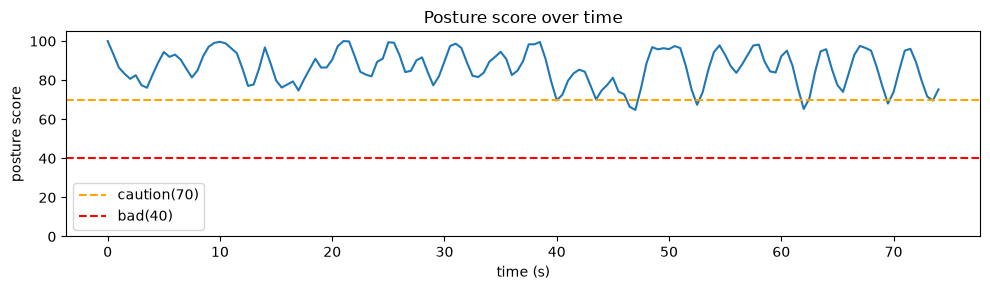

In [9]:
plt.figure(figsize=(10,3))
plt.plot(np.arange(len(hist))/analysis_fps, hist)
plt.axhline(70, ls="--", c="orange", label="caution(70)")
plt.axhline(40, ls="--", c="red", label="bad(40)")
plt.xlabel("time (s)"); plt.ylabel("posture score"); plt.ylim(0,105)
plt.title("Posture score over time"); plt.legend(); plt.tight_layout(); plt.show()

## STEP 3. 지표 52개로 정리

위 세 분석 결과를 평가모델 입력 형태(숫자 52개)로 변환한다.
`extract_features.py` 가 만든 결과와 동일하므로 저장된 JSON을 불러와 확인한다.

In [10]:
feat = json.loads((CSM / "eval_model/data/features" / f"{VIDEO_ID}.json").read_text(encoding="utf-8"))
drop = {"video_id","class_dir","video_path","errors","elapsed_sec","frames_sampled"}
features = {k: v for k, v in feat.items() if k not in drop}

s = pd.Series(features, name="값").to_frame()
s["구분"] = ["음성" if i < 17 else "시선/표정" if i < 34 else "자세" for i in range(len(s))]
print(f"총 {len(s)}개 지표\n")
for group in ["음성", "시선/표정", "자세"]:
    sub = s[s.구분 == group]
    print(f"── {group} ({len(sub)}개) ──")
    print(sub[["값"]].to_string(float_format=lambda x: f"{x:10.3f}"))
    print()

총 52개 지표

── 음성 (17개) ──
                              값
spm                     261.300
filler_count              4.000
filler_per_min            3.225
stutter_count             0.000
stutter_per_min           0.000
long_pause_count          3.000
long_pause_per_min        2.418
long_pause_total_sec     12.020
long_pause_max_sec        6.590
long_pause_ratio          0.161
volume_rms_mean           0.055
volume_rms_std            0.032
volume_cv                 0.589
total_duration_sec       74.430
pure_speech_time_sec     55.560
speech_ratio              0.746
word_count               93.000

── 시선/표정 (17개) ──
                                 값
gaze_center_ratio            0.540
gaze_left_ratio              0.090
gaze_right_ratio             0.020
gaze_up_ratio                0.000
gaze_down_ratio              0.180
gaze_blink_ratio             0.170
gaze_deviation_count        29.000
gaze_deviation_mean_sec      0.759
gaze_deviation_max_sec       3.500
face_detect_ratio            1

## STEP 4. 평가모델 — 항목별 점수 7개 예측

**핵심**: 이 영상 촬영자(`이영은`)의 영상 4개를 학습 데이터에서 모두 빼고 학습한다.
즉 모델은 이 사람을 한 번도 본 적 없는 상태에서 예측한다 (실제 신규 사용자와 동일한 조건).

In [11]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV

TARGETS = {"말속도":("발화속도",15), "명확성":("말하기안정성",15), "침묵":("유창성침묵",15),
           "습관어":("습관어반복",10), "시선비율":("시선처리",15), "표정":("표정자연스러움",15),
           "상반신자세":("자세움직임",15)}

df = pd.read_csv(CSM / "eval_model/data/dataset.csv")
feature_cols = [c for c in df.columns
                if c not in {"video_id","class_dir","elapsed_sec","frames_sampled",
                             "label_score","group"} | set(TARGETS)]

train_df = df[df.group != PERSON]          # ← 같은 사람 전부 제외
print(f"전체 {len(df)}행 → 학습 {len(train_df)}행 ('{PERSON}' 의 {len(df)-len(train_df)}개 제외)")

x_new = pd.DataFrame([{c: features.get(c, np.nan) for c in feature_cols}])

pred_items = {}
for col, (item, weight) in TARGETS.items():
    model = Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler()),
                      ("model", RidgeCV(alphas=[0.1,1.0,10.0,100.0,1000.0]))])
    model.fit(train_df[feature_cols], train_df[col])
    pred_items[item] = float(np.clip(model.predict(x_new)[0], 1.0, 5.0))

for item, score in pred_items.items():
    print(f"  {item:<12}: {score:.2f} / 5.00")

전체 33행 → 학습 29행 ('이영은' 의 4개 제외)
  발화속도        : 2.63 / 5.00
  말하기안정성      : 4.17 / 5.00
  유창성침묵       : 1.00 / 5.00
  습관어반복       : 1.79 / 5.00
  시선처리        : 2.07 / 5.00
  표정자연스러움     : 3.51 / 5.00
  자세움직임       : 2.11 / 5.00


## STEP 5. 총점 계산

채점표 수식 그대로: `총점 = Σ ((항목점수 − 1) / 4) × 가중치`

In [12]:
rows = []
for col, (item, weight) in TARGETS.items():
    score = pred_items[item]
    contribution = (score - 1) / 4 * weight
    rows.append({"항목": item, "가중치": weight, "예측점수": round(score,2),
                 "환산점수": round(contribution,2), "만점": weight})
tbl = pd.DataFrame(rows)
total = tbl.환산점수.sum()

print(tbl.to_string(index=False))
print(f"\n총점: {total:.1f} / 100")

true_total = float(df[df.video_id == VIDEO_ID].label_score.iloc[0])
print(f"사람 채점: {true_total:.1f} / 100")
print(f"오차: {total - true_total:+.1f}점")

     항목  가중치  예측점수  환산점수  만점
   발화속도   15  2.63  6.13  15
 말하기안정성   15  4.17 11.88  15
  유창성침묵   15  1.00  0.00  15
  습관어반복   10  1.79  1.98  10
   시선처리   15  2.07  4.01  15
표정자연스러움   15  3.51  9.40  15
  자세움직임   15  2.11  4.16  15

총점: 37.6 / 100
사람 채점: 35.0 / 100
오차: +2.6점


## STEP 6. 사용자 리포트

In [13]:
def grade(score5):
    return ["매우 미흡","미흡","보통","우수","매우 우수"][min(int(round(score5))-1, 4)]

print("="*58)
print(f"  모의면접 분석 리포트   ({VIDEO_ID})")
print("="*58)
print(f"\n  종합 점수:  {total:.1f} / 100\n")
print("  [ 항목별 점수 ]")
for _, r in tbl.sort_values("예측점수").iterrows():
    bar = "█" * int(round(r.예측점수 * 4)) + "░" * (20 - int(round(r.예측점수 * 4)))
    print(f"   {r.항목:<12} {bar} {r.예측점수:.1f}/5.0  {grade(r.예측점수)}")

print("\n  [ 개선이 필요한 부분 ]")
weak = tbl.nsmallest(3, "예측점수")
tips = {
    "발화속도": f"측정 발화속도 {m['speech_rate']['spm']}spm — 적정 구간(270~350spm) 대비 조절 필요",
    "말하기안정성": f"음량 변동계수 {m['volume_stability']['cv']} — 일정한 크기로 또렷하게",
    "유창성침묵": f"2초 이상 침묵 {m['long_pauses']['count']}회 — 답변 구조를 미리 정리해 두기",
    "습관어반복": f"습관어 {m['filler_word']['count']}회 — '음', '어' 대신 짧게 쉬기",
    "시선처리": f"정면 응시 {gaze['gaze_ratio']*100:.0f}% — 카메라 렌즈를 보는 연습 필요",
    "표정자연스러움": "답변 내용에 맞는 표정 변화가 부족 — 굳은 표정 완화 필요",
    "자세움직임": f"자세 점수 평균 {np.mean(hist):.0f}/100 — 상체 흔들림 줄이기",
}
for _, r in weak.iterrows():
    print(f"   • {r.항목} ({r.예측점수:.1f}/5.0)")
    print(f"     {tips[r.항목]}")

print("\n  [ 다시 확인할 구간 ]")
for p in m["long_pauses"]["occurrences"][:3]:
    if p.get("start") is None: continue
    print(f"   • {p['start']:.0f}s ~ {p['end']:.0f}s : 긴 침묵 {p['duration']:.1f}초")
for s_ in gaze["deviated_segments"][:3]:
    if s_["end"] - s_["start"] >= 1.0:
        print(f"   • {s_['start']:.0f}s ~ {s_['end']:.0f}s : 시선 이탈({s_['direction']})")
print("\n" + "="*58)

  모의면접 분석 리포트   (이영은_bad)

  종합 점수:  37.6 / 100

  [ 항목별 점수 ]
   유창성침묵        ████░░░░░░░░░░░░░░░░ 1.0/5.0  매우 미흡
   습관어반복        ███████░░░░░░░░░░░░░ 1.8/5.0  미흡
   시선처리         ████████░░░░░░░░░░░░ 2.1/5.0  미흡
   자세움직임        ████████░░░░░░░░░░░░ 2.1/5.0  미흡
   발화속도         ███████████░░░░░░░░░ 2.6/5.0  보통
   표정자연스러움      ██████████████░░░░░░ 3.5/5.0  우수
   말하기안정성       █████████████████░░░ 4.2/5.0  우수

  [ 개선이 필요한 부분 ]
   • 유창성침묵 (1.0/5.0)
     2초 이상 침묵 3회 — 답변 구조를 미리 정리해 두기
   • 습관어반복 (1.8/5.0)
     습관어 4회 — '음', '어' 대신 짧게 쉬기
   • 시선처리 (2.1/5.0)
     정면 응시 54% — 카메라 렌즈를 보는 연습 필요

  [ 다시 확인할 구간 ]
   • 31s ~ 34s : 긴 침묵 3.3초
   • 43s ~ 46s : 긴 침묵 2.2초
   • 48s ~ 54s : 긴 침묵 6.6초

